In [1]:
import pandas as pd
import numpy as np

In [30]:
df=pd.read_csv("Dataset-Coginifiyz.csv",encoding='utf-8-sig')
df.head(1)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314


In [31]:
df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()

In [32]:
df.shape

(9551, 21)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [34]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
c=df.copy()
c['Cuisines']=c['Cuisines'].fillna('Unknown')
c['Main']=c['Cuisines'].str.split(",").str[0].str.strip()
c=c[c['Main']!="Unknown"]

top=c['Main'].value_counts().head(10).index
c=c[c['Main'].isin(top)]
c['Main'].value_counts()

Main
North Indian    2992
Chinese          855
Fast Food        672
Bakery           621
Cafe             617
American         278
South Indian     262
Mithai           246
Street Food      236
Continental      235
Name: count, dtype: int64

In [37]:
feat = c[["City", "Price range", "Average Cost for two", "Aggregate rating",
          "Votes", "Has Table booking", "Has Online delivery",
          "Latitude", "Longitude"]].copy()

for col in ["Has Table booking", "Has Online delivery"]:
    feat[col] = feat[col].map({"Yes": 1, "No": 0})

feat = pd.get_dummies(feat, columns=["City"], drop_first=True)
yc = c["Main"]

In [38]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    feat, yc, test_size=0.2, random_state=42, stratify=yc)

In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

clf = {
    "Logistic": make_pipeline(StandardScaler(),
                LogisticRegression(max_iter=1000, class_weight="balanced")),
    "RandomForest": RandomForestClassifier(n_estimators=200, n_jobs=-1,
                    class_weight="balanced", random_state=42),
}
for name, m in clf.items():
    m.fit(Xc_train, yc_train)
    print(name, "accuracy:", round(accuracy_score(yc_test, m.predict(Xc_test))*100, 3))

Logistic accuracy: 19.601
RandomForest accuracy: 44.12


In [40]:
rfc = clf["RandomForest"]
pred = rfc.predict(Xc_test)
print(classification_report(yc_test, pred))

              precision    recall  f1-score   support

    American       0.64      0.52      0.57        56
      Bakery       0.25      0.17      0.20       124
        Cafe       0.41      0.28      0.34       123
     Chinese       0.17      0.09      0.12       171
 Continental       0.26      0.11      0.15        47
   Fast Food       0.21      0.12      0.15       135
      Mithai       0.34      0.27      0.30        49
North Indian       0.52      0.78      0.62       599
South Indian       0.13      0.04      0.06        52
 Street Food       0.34      0.26      0.29        47

    accuracy                           0.44      1403
   macro avg       0.33      0.26      0.28      1403
weighted avg       0.38      0.44      0.39      1403



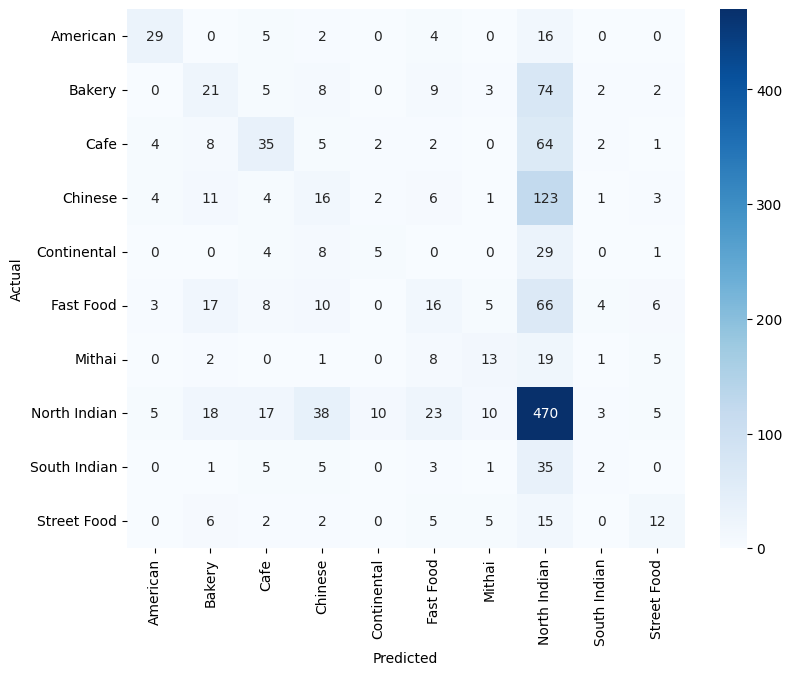

In [41]:
labels = sorted(yc.unique())
cm = confusion_matrix(yc_test, pred, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [42]:
sample = Xc_test.iloc[[0]]
print("Predicted:", rfc.predict(sample)[0])
print("Actual   :", yc_test.iloc[0])

Predicted: North Indian
Actual   : North Indian


In [43]:
def predict_cuisine(city, price_range, avg_cost, rating, votes,
                    table_booking=0, online_delivery=0,
                    latitude=0, longitude=0, model=rfc, top_k=3):
    row = pd.DataFrame(0, index=[0], columns=feat.columns)

    row["Price range"] = price_range
    row["Average Cost for two"] = avg_cost
    row["Aggregate rating"] = rating
    row["Votes"] = votes
    row["Has Table booking"] = table_booking
    row["Has Online delivery"] = online_delivery
    row["Latitude"] = latitude
    row["Longitude"] = longitude

    col = f"City_{city}"
    if col in row.columns:
        row[col] = 1
    else:
        print(f"Note: '{col}' training data mein nahi tha, ignore kiya")

    probs = model.predict_proba(row)[0]
    top = np.argsort(probs)[::-1][:top_k]
    return [(model.classes_[i], round(probs[i] * 100, 1)) for i in top]

In [44]:
predict_cuisine(city="New Delhi", price_range=2, avg_cost=600,
                rating=3.8, votes=250,
                table_booking=0, online_delivery=1,
                latitude=28.63, longitude=77.21)

[('North Indian', 42.5), ('Cafe', 30.5), ('Chinese', 13.5)]

In [45]:
dff=predict_cuisine(city="New Delhi", price_range=2, avg_cost=600,
                rating=3.8, votes=250,
                table_booking=0, online_delivery=1,
                latitude=28.63, longitude=77.21)

In [46]:
d=pd.DataFrame(dff)
d

,0,1
0,North Indian,42.5
1,Cafe,30.5
2,Chinese,13.5


In [51]:
import joblib

In [52]:
joblib.dump(rfc, "task3_cuisine_model.joblib")

['task3_cuisine_model.joblib']